# Рекомендательная система фильмов

Данные: MovieLens — 100 836 оценок, 610 пользователей, 9 742 фильма, постеры и описания из TMDB.

Что делаем:
1. смотрим на данные;
2. обучаем модель — три подхода: **популярность**, **SVD** (по оценкам), **контент** (жанры + описание);
3. объединяем их в гибрид и проверяем качество (Precision@10 / Recall@10);
4. сохраняем модель в отдельный файл.

Сам код модели лежит в **`recommender.py`** — ноутбук только вызывает его.

## 1. Данные

In [1]:
import sys
sys.path.insert(0, 'files')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recommender import Recommender

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 50)

movies = pd.read_csv("movies.csv")
ratings = pd.read_csv("ratings (1).csv")
photo = pd.read_csv("photo.csv")

print("фильмов:", len(movies), "| оценок:", len(ratings), "| пользователей:", ratings.userId.nunique())
print("заполненность матрицы: {:.2%}".format(len(ratings) / (ratings.userId.nunique() * ratings.movieId.nunique())))
movies[["movieId", "title", "year", "genres"]].astype({"year": "Int64"}).head()

фильмов: 9742 | оценок: 100836 | пользователей: 610
заполненность матрицы: 1.70%


,movieId,title,year,genres
0,1,Toy Story (1995),1995,Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),1995,Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),1995,Comedy|Romance
3,4,Waiting to Exhale (1995),1995,Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),1995,Comedy


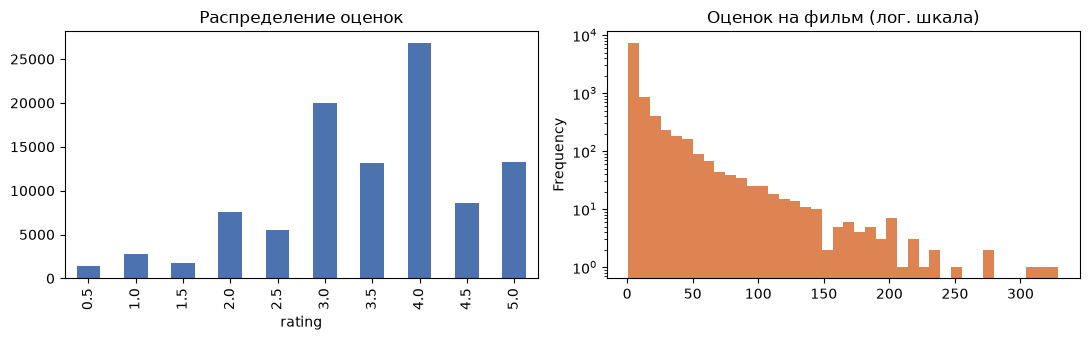

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="#4c72b0")
ax[0].set_title("Распределение оценок")
ratings.groupby("movieId").size().plot.hist(bins=40, log=True, ax=ax[1], color="#dd8452")
ax[1].set_title("Оценок на фильм (лог. шкала)")
plt.tight_layout()
plt.show()

Матрица оценок заполнена на 1.70 % (100 836 оценок из 610 × 9 724), а у большинства фильмов оценок совсем мало: медиана — 3 оценки, у 3 446 фильмов — ровно одна. Порог в 20 оценок оставляет 1 297 кандидатов.

### Пропуски и дубликаты

In [3]:
rows = []
for name, df in [("movies", movies), ("ratings", ratings), ("photo", photo)]:
    for col in df.columns:
        n = int(df[col].isna().sum())
        if n:
            rows.append({"файл": name, "колонка": col, "пропусков": n, "доля, %": 100 * n / len(df)})
miss = pd.DataFrame(rows).sort_values("пропусков", ascending=False).reset_index(drop=True)
print("строк с пропусками в ratings:", int(ratings.isna().any(axis=1).sum()),
      "| дубликатов строк:", int(ratings.duplicated().sum()),
      "| повторных пар (user, film):", int(ratings.duplicated(["userId", "movieId"]).sum()))
print("movieId без единой оценки:", int((~movies.movieId.isin(ratings.movieId)).sum()),
      "| оценок к отсутствующим фильмам:", int((~ratings.movieId.isin(movies.movieId)).sum()))
miss

строк с пропусками в ratings: 0 | дубликатов строк: 0 | повторных пар (user, film): 0
movieId без единой оценки: 18 | оценок к отсутствующим фильмам: 0


,файл,колонка,пропусков,"доля, %"
0,photo,poster_url,87,0.893
1,photo,overview,85,0.873
2,movies,year,13,0.133
3,movies,tmdbId,8,0.082
4,photo,tmdbId,8,0.082


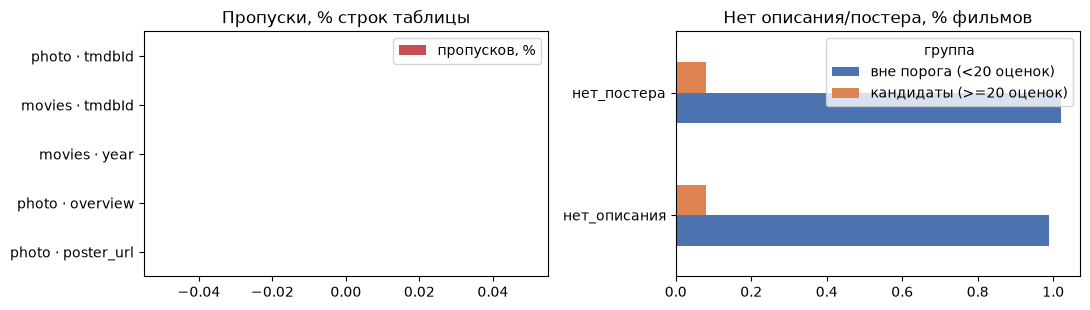

,нет_описания,нет_постера
группа,,
вне порога (<20 оценок),0.990,1.020
кандидаты (>=20 оценок),0.080,0.080


In [4]:
votes_by_movie = ratings.groupby("movieId").size().reindex(movies.movieId).fillna(0)
cov = movies.assign(votes=votes_by_movie.values).merge(photo[["movieId", "overview", "poster_url"]], on="movieId", how="outer")
cov["группа"] = np.where(cov.votes >= 20, "кандидаты (>=20 оценок)", "вне порога (<20 оценок)")
cov["нет описания"] = cov.overview.isna()
cov["нет постера"] = cov.poster_url.isna()
by_group = cov.groupby("группа").agg(фильмов=("movieId", "size"), нет_описания=("нет описания", "sum"), нет_постера=("нет постера", "sum"))
by_group = (by_group.iloc[:, 1:] / by_group[["фильмов"]].values * 100).round(2)

miss_plot = pd.DataFrame({"пропусков, %": miss["доля, %"]},
                         index=miss["файл"] + " · " + miss["колонка"]).sort_values("пропусков, %")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
miss_plot.plot.barh(ax=ax[0], color="#c44e52")
ax[0].set_title("Пропуски, % строк таблицы"); ax[0].set_ylabel("")
by_group.T.plot.barh(ax=ax[1], color=["#4c72b0", "#dd8452"])
ax[1].set_title("Нет описания/постера, % фильмов"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()
by_group

**Факты по пропускам**

- В `ratings` пропусков и дубликатов нет: 100 836 уникальных пар «пользователь — фильм», оценки в диапазоне 0.5–5.0.
- Пропуски есть только в описательных колонках: `year` — 13 (0.1 %), `tmdbId` — 8, `poster_url` — 87 (0.9 %), `overview` — 85 (0.9 %).
- 18 фильмов не имеют ни одной оценки, оценок «в никуда» (filmId отсутствует в `movies`) — 0.
- Среди 1 297 фильмов, прошедших порог в 20 оценок, описание и постер отсутствуют только у одного: на контентную часть пропуски практически не влияют.

### Годы выпуска и жанры

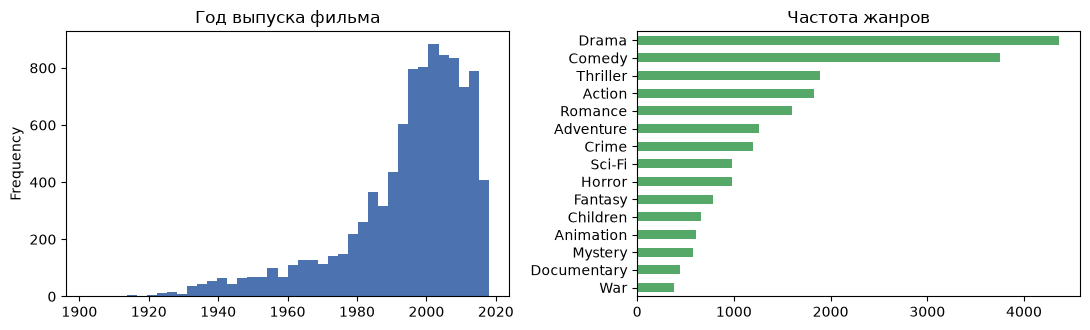

годы: 1902 - 2018 | медиана 1999 | без года 13
2000 и позже: 49.1% | 1950 и раньше: 4.1%
жанров на фильм: в среднем 2.27, максимум 10, один жанр у 29.3%
без жанра: 34


In [5]:
genres_list = movies.genres.str.split("|")
top_genres = pd.Series([g for row in genres_list for g in row]).value_counts().head(15)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
movies.year.dropna().plot.hist(bins=40, ax=ax[0], color="#4c72b0")
ax[0].set_title("Год выпуска фильма")
top_genres[::-1].plot.barh(ax=ax[1], color="#55a868")
ax[1].set_title("Частота жанров"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

print("годы:", int(movies.year.min()), "-", int(movies.year.max()), "| медиана", int(movies.year.median()),
      "| без года", int(movies.year.isna().sum()))
print("2000 и позже: {:.1%} | 1950 и раньше: {:.1%}".format((movies.year >= 2000).mean(), (movies.year <= 1950).mean()))
print("жанров на фильм: в среднем {:.2f}, максимум {}, один жанр у {:.1%}".format(
    genres_list.str.len().mean(), genres_list.str.len().max(), (genres_list.str.len() == 1).mean()))
print("без жанра:", int((movies.genres == "(no genres listed)").sum()))

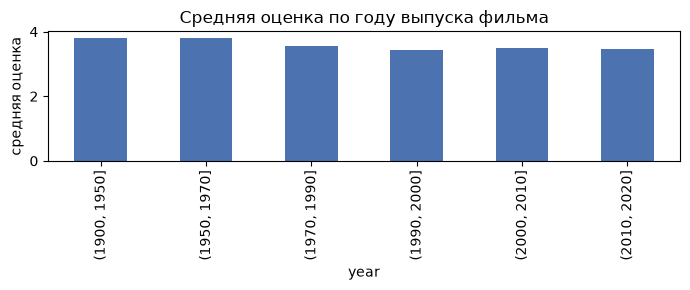

In [6]:
by_age = ratings.merge(movies[["movieId", "year"]], on="movieId").dropna(subset=["year"])
by_age.groupby(pd.cut(by_age.year, [1900, 1950, 1970, 1990, 2000, 2010, 2020]), observed=True).rating.mean().round(2).plot.bar(
    figsize=(7, 3), color="#4c72b0")
plt.ylabel("средняя оценка"); plt.title("Средняя оценка по году выпуска фильма")
plt.tight_layout(); plt.show()

**Факты по годам и жанрам**

- Год выпуска: 1902–2018, медиана — 1999; половина каталога (49 %) — фильмы 2000 года и позже, 4 % — фильмы до 1950 года.
- Жанров у фильма в среднем 2.27 (максимум 10), у 29 % ровно один, у 34 фильмов жанра нет вовсе.
- Drama (4 361) и Comedy (3 756) встречаются чаще всего; хотя бы один из них есть у 73 % фильмов.
- Средние оценки старых фильмов выше: ленты до 1950 года — 3.81, 1950–1970 — 3.82, 1990-е — 3.43, 2010-е — 3.47.

### Кто и как оценивает

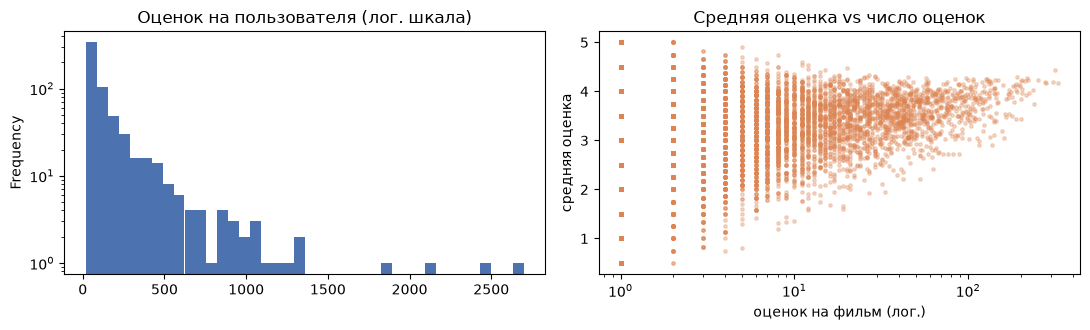

оценок на пользователя: мин 20 медиана 70.5 макс 2698 | 95-й процентиль 610
10 самых активных пользователей: 16.3% всех оценок
оценок >=4: 48.2% | оценок <=2: 13.4% | средняя 3.50
средние по пользователям: от 1.27 до 5.00 (разброс 0.48), разброс внутри пользователя 0.93
связь «число оценок — средняя оценка»: r = 0.104


In [7]:
per_user = ratings.groupby("userId").size()
stats = ratings.groupby("movieId").rating.agg(votes="count", mean="mean")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
per_user.plot.hist(bins=40, log=True, ax=ax[0], color="#4c72b0")
ax[0].set_title("Оценок на пользователя (лог. шкала)")
ax[1].scatter(stats.votes, stats["mean"], s=6, alpha=0.3, color="#dd8452")
ax[1].set_xscale("log"); ax[1].set_xlabel("оценок на фильм (лог.)")
ax[1].set_ylabel("средняя оценка"); ax[1].set_title("Средняя оценка vs число оценок")
plt.tight_layout(); plt.show()

print("оценок на пользователя: мин", int(per_user.min()), "медиана", per_user.median(),
      "макс", int(per_user.max()), "| 95-й процентиль", int(per_user.quantile(.95)))
print("10 самых активных пользователей: {:.1%} всех оценок".format(per_user.nlargest(10).sum() / len(ratings)))
print("оценок >=4: {:.1%} | оценок <=2: {:.1%} | средняя {:.2f}".format((ratings.rating >= 4).mean(), (ratings.rating <= 2).mean(), ratings.rating.mean()))
print("средние по пользователям: от {:.2f} до {:.2f} (разброс {:.2f}), разброс внутри пользователя {:.2f}".format(
    ratings.groupby("userId").rating.mean().min(), ratings.groupby("userId").rating.mean().max(),
    ratings.groupby("userId").rating.mean().std(), ratings.groupby("userId").rating.std().mean()))
print("связь «число оценок — средняя оценка»: r = {:.3f}".format(np.corrcoef(np.log(stats.votes), stats["mean"])[0, 1]))

**Факты по оценкам и активности**

- Все 610 пользователей оставили минимум 20 оценок, но распределение резкое: медиана — 70 оценок, 95-й процентиль — 610, максимум — 2 698.
- На 10 самых активных пользователей приходится 16 % оценок, на 100 самых оцениваемых фильмов — тоже 16 %.
- Оценок 4 и выше — 48 %, оценок 2 и ниже — 13 %; средняя оценка 3.50 при стандартном отклонении 1.04.
- Пользователи смещают шкалу: их средние лежат в диапазоне 1.27–5.00 (σ = 0.48), а разброс оценок внутри одного пользователя — σ = 0.93.
- Популярность почти не связана с оценкой: r(log-число оценок, средняя оценка) = 0.10.
- Порог в 20 оценок оставляет 1 297 фильмов (13 % каталога), но на них приходится 67 % всех оценок.

## 2. Обучение модели

Класс `Recommender` делает следующее:
- **популярность** — взвешенный рейтинг IMDb: `(v·R + m·C) / (v + m)`, чтобы фильм с одной пятёркой не обгонял фильм с тысячей оценок;
- **SVD** — оценки пользователей (за вычетом его среднего) раскладываются на 40 скрытых факторов; по ним считается и сходство фильмов, и баллы для пользователя;
- **контент** — TF-IDF по жанрам и описанию фильма; профиль вкуса = средний вектор фильмов, которые пользователь оценил на 4 и выше;
- **гибрид** = 0.7 · SVD + 0.3 · контент.

In [8]:
model = Recommender(n_factors=40, alpha=0.7, min_votes=20).fit(movies, ratings, photo)
model.popular(10)[["title", "genres", "votes", "score"]]

,title,genres,votes,score
0,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.337
1,"Godfather, The (1972)",Crime|Drama,192,4.162
2,Fight Club (1999),Action|Crime|Drama|Thriller,218,4.162
3,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251,4.137
4,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,204,4.124
5,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.122
6,Schindler's List (1993),Drama|War,220,4.120
7,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.110
8,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,211,4.108
9,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.096


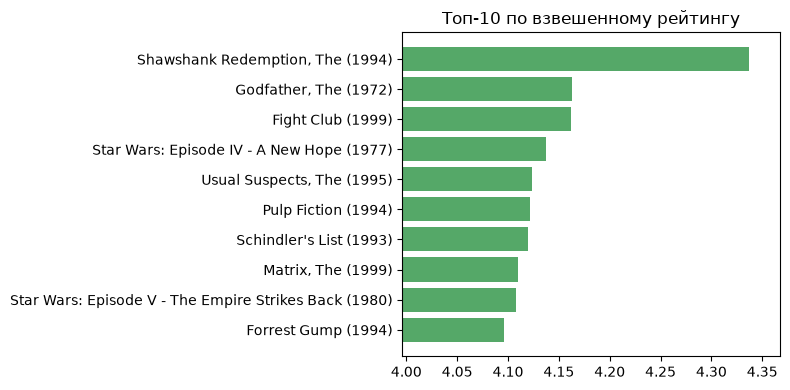

In [9]:
top = model.popular(10)
plt.figure(figsize=(8, 4))
plt.barh(top.title[::-1], top.score[::-1], color="#55a868")
plt.xlim(top.score.min() - 0.1, top.score.max() + 0.03)
plt.title("Топ-10 по взвешенному рейтингу")
plt.tight_layout()
plt.show()

In [10]:
model.popular(5, genre="Comedy")[["title", "votes", "score"]]

,title,votes,score
0,Pulp Fiction (1994),307,4.122
1,Forrest Gump (1994),329,4.096
2,"Princess Bride, The (1987)",142,4.077
3,Dr. Strangelove or: How I Learned to Stop Worr...,97,4.049
4,"Amelie (Fabuleux destin d'Amélie Poulain, Le) ...",120,4.014


## 3. Похожие фильмы

In [11]:
# по оценкам пользователей (SVD)
model.similar("Toy Story (1995)", 10, by="svd")[["title", "genres", "similarity"]]

,title,genres,similarity
0,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.594
1,Back to the Future (1985),Adventure|Comedy|Sci-Fi,0.479
2,Blazing Saddles (1974),Comedy|Western,0.452
3,Babe (1995),Children|Drama,0.439
4,"Incredibles, The (2004)",Action|Adventure|Animation|Children|Comedy,0.437
5,Beauty and the Beast (1991),Animation|Children|Fantasy|Musical|Romance|IMAX,0.435
6,Wallace & Gromit: The Wrong Trousers (1993),Animation|Children|Comedy|Crime,0.432
7,Love Actually (2003),Comedy|Drama|Romance,0.419
8,Ghostbusters (a.k.a. Ghost Busters) (1984),Action|Comedy|Sci-Fi,0.404
9,Billy Elliot (2000),Drama,0.404


In [12]:
# по жанрам и описанию (контент)
model.similar("Matrix, The", 10, by="content")[["title", "genres", "similarity"]]

,title,genres,similarity
0,Hackers (1995),Action|Adventure|Crime|Thriller,0.199
1,"Animatrix, The (2003)",Action|Animation|Drama|Sci-Fi,0.169
2,Avatar (2009),Action|Adventure|Sci-Fi|IMAX,0.157
3,Live Free or Die Hard (2007),Action|Adventure|Crime|Thriller,0.151
4,"Lawnmower Man, The (1992)",Action|Horror|Sci-Fi|Thriller,0.128
5,"Matrix Reloaded, The (2003)",Action|Adventure|Sci-Fi|Thriller|IMAX,0.123
6,Rocky III (1982),Action|Drama,0.119
7,Little Big Man (1970),Western,0.116
8,WarGames (1983),Drama|Sci-Fi|Thriller,0.114
9,Mad Max: Fury Road (2015),Action|Adventure|Sci-Fi|Thriller,0.111


## 4. Персональные рекомендации

In [13]:
user = 1
fav = ratings[ratings.userId == user].nlargest(8, "rating").merge(movies, on="movieId")
fav[["title", "genres", "rating"]]

,title,genres,rating
0,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,5.000
1,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.000
2,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance,5.000
3,Rob Roy (1995),Action|Drama|Romance|War,5.000
4,Canadian Bacon (1995),Comedy|War,5.000
5,Desperado (1995),Action|Romance|Western,5.000
6,Billy Madison (1995),Comedy,5.000
7,Dumb & Dumber (Dumb and Dumber) (1994),Adventure|Comedy,5.000


In [14]:
model.recommend_user(user, 10)[["title", "genres", "score"]]

,title,genres,score
0,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi,0.678
1,Blade Runner (1982),Action|Sci-Fi|Thriller,0.674
2,Gattaca (1997),Drama|Sci-Fi|Thriller,0.648
3,North by Northwest (1959),Action|Adventure|Mystery|Romance|Thriller,0.638
4,Mary Poppins (1964),Children|Comedy|Fantasy|Musical,0.637
5,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy,0.616
6,"Little Mermaid, The (1989)",Animation|Children|Comedy|Musical|Romance,0.612
7,"Sound of Music, The (1965)",Musical|Romance,0.589
8,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,0.587
9,"City of Lost Children, The (Cité des enfants p...",Adventure|Drama|Fantasy|Mystery|Sci-Fi,0.585


Новый пользователь: достаточно нескольких оценок — модель «складывает» его в то же SVD-пространство, переобучать ничего не нужно.

In [15]:
new_user = {
    model.find("Matrix, The"): 5,
    model.find("Inception"): 5,
    model.find("Interstellar"): 4.5,
    model.find("Titanic (1997)"): 2,
}
model.recommend(new_user, 10)[["title", "genres", "score"]]

,title,genres,score
0,Fight Club (1999),Action|Crime|Drama|Thriller,0.492
1,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,0.485
2,Memento (2000),Mystery|Thriller,0.474
3,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,0.450
4,"South Park: Bigger, Longer and Uncut (1999)",Animation|Comedy|Musical,0.447
5,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,0.446
6,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,0.444
7,Die Hard (1988),Action|Crime|Thriller,0.435
8,Gattaca (1997),Drama|Sci-Fi|Thriller,0.433
9,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,0.430


## 5. Проверка качества

Для каждого пользователя прячем 20 % его хороших оценок (≥ 4). Модель переобучается на остальном и строит топ-10 — смотрим, сколько спрятанных фильмов она угадала.
- **Precision@10** — доля угаданных среди 10 рекомендаций;
- **Recall@10** — доля найденных из спрятанных.

Базовый уровень — «всем одинаковый топ популярных».

In [16]:
good = ratings[ratings.rating >= 4]
test_idx = good.groupby("userId", group_keys=False).apply(
    lambda g: g.sample(frac=0.2, random_state=42) if len(g) >= 5 else g.iloc[0:0]).index
train, test = ratings.drop(test_idx), ratings.loc[test_idx]

m_eval = Recommender().fit(movies, train, photo)
train_by_user = train.groupby("userId").apply(lambda g: dict(zip(g.movieId, g.rating)))


def evaluate(score_fn, k=10):
    P, R = [], []
    for u, g in test.groupby("userId"):
        seen = train_by_user[u]
        s = score_fn(seen).copy()
        s[~m_eval.ok] = -np.inf
        for mid in seen:
            s[m_eval.pos[mid]] = -np.inf
        top = m_eval.movies.index[np.argsort(-s)[:k]]
        hits = len(set(top) & set(g.movieId))
        P.append(hits / k)
        R.append(hits / len(g))
    return {"Precision@10": np.mean(P), "Recall@10": np.mean(R)}


results = pd.DataFrame({
    "Популярные":      evaluate(lambda s: m_eval.movies.score.values),
    "SVD":             evaluate(lambda s: m_eval.scores(s, alpha=1.0)),
    "Контент":         evaluate(lambda s: m_eval.scores(s, alpha=0.0)),
    "Гибрид (0.7/0.3)": evaluate(lambda s: m_eval.scores(s, alpha=0.7)),
}).T
results

,Precision@10,Recall@10
Популярные,0.117,0.100
SVD,0.136,0.118
Контент,0.037,0.037
Гибрид (0.7/0.3),0.143,0.129


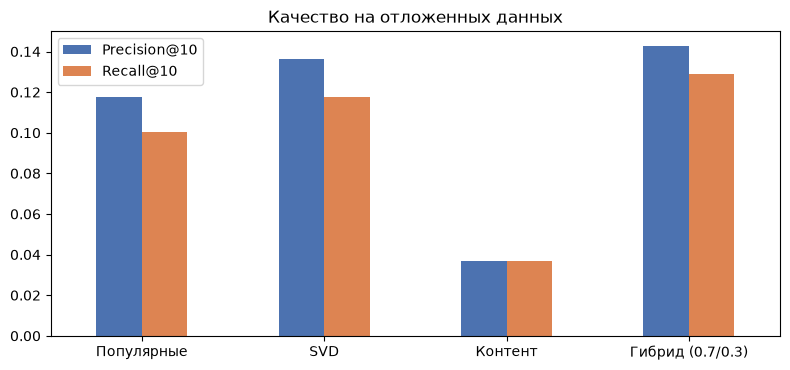

In [17]:
results.plot.bar(figsize=(8, 3.8), rot=0, color=["#4c72b0", "#dd8452"])
plt.title("Качество на отложенных данных")
plt.tight_layout()
plt.show()

## 6. Сохранение модели

In [18]:
final = Recommender(n_factors=40, alpha=0.7, min_votes=20).fit(movies, ratings, photo)
final.save("/tmp/nb_model_check.pkl")

# проверка: загружаем из файла и получаем рекомендации
loaded = Recommender.load("/tmp/nb_model_check.pkl")
loaded.recommend({loaded.find("Toy Story (1995)"): 5, loaded.find("Lion King, The"): 5}, 5)[["title", "genres", "score"]]

,title,genres,score
0,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.171
1,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.145
2,"40-Year-Old Virgin, The (2005)",Comedy|Romance,0.094
3,Man on the Moon (1999),Comedy|Drama,0.049
4,"Little Mermaid, The (1989)",Animation|Children|Comedy|Musical|Romance,0.041


## Выводы

- Precision@10: популярные — 0.117, SVD — 0.136, контент — 0.037, гибрид 0.7/0.3 — 0.143. Recall@10: 0.100, 0.118, 0.037, 0.129.
- Гибрид выше базового уровня по популярности на 22 % по Precision@10 и на 29 % по Recall@10; SVD отдельно — на 16 % и 18 %.
- Контент по жанрам и описанию отдельно втрое ниже популярного топа, но в смеси с SVD добавляет ему 5 % Precision@10 и 9 % Recall@10.
- Порог в 20 оценок сокращает список кандидатов с 9 742 до 1 297 фильмов, за которыми остаётся 67 % всех оценок.
- Пропуски (year — 0.1 %, overview и poster_url — по 0.9 %) выпадают на 1 фильм из 1 297 кандидатов.
- Пользователя вне обучающей выборки модель переводит в SVD-пространство по его оценкам: 4 оценок достаточно, чтобы топ-10 отличался от популярного; без оценок возвращаются баллы популярности.